In [55]:
import numpy as np
import pandas as pd

In [56]:
df= pd.read_csv("language.csv")

In [57]:
df.head(10)

,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch
5,エノが行きがかりでバスに乗ってしまい、気分が悪くなった際に助けるが、今すぐバスを降りたいと運...,Japanese
6,tsutinalar i̇ngilizce tsuutina kanadada albert...,Turkish
7,müller mox figura centralis circulorum doctoru...,Latin
8,برقی بار electric charge تمام زیرجوہری ذرات کی...,Urdu
9,シャーリー・フィールドは、サン・ベルナルド・アベニュー沿い市民センターとrtマーティン高校に...,Japanese


In [3]:
print("Total rows:\n", len(df))

Total rows:
 22000


In [4]:
print("Total col:\n", len(df.columns))

Total col:
 2


In [5]:
df.dtypes

Text        str
language    str
dtype: object

In [6]:
df.isnull().sum()

Text        0
language    0
dtype: int64

In [7]:
df["language"].value_counts()

language
Estonian      1000
Swedish       1000
Thai          1000
Tamil         1000
Dutch         1000
Japanese      1000
Turkish       1000
Latin         1000
Urdu          1000
Indonesian    1000
Portugese     1000
French        1000
Chinese       1000
Korean        1000
Hindi         1000
Spanish       1000
Pushto        1000
Persian       1000
Romanian      1000
Russian       1000
English       1000
Arabic        1000
Name: count, dtype: int64

In [8]:
df['Text'].duplicated().sum()

np.int64(141)

In [9]:
print(f"\nTotal missing: {df.isnull().sum().sum()}")
print(f"Duplicate texts: {df['Text'].duplicated().sum()}")


Total missing: 0
Duplicate texts: 141


In [10]:
# Features and Target
X = df['Text']
y = df['language']

In [11]:
import time
from sklearn.feature_extraction.text import TfidfVectorizer  #TF = Term Frequency,IDF = Inverse Document Frequency


In [12]:
start_time = time.time()
tfidf = TfidfVectorizer(
    analyzer='char_wb',        # Character-level
    ngram_range=(1, 3),         # 1-3 char n-grams
    max_features=50000,         # Top 50,000 features
    lowercase=True,
    sublinear_tf=True           # Log scaling
)
X_tfidf = tfidf.fit_transform(X)

vectorize_time = time.time() - start_time

In [13]:
print(f"Vectorization time: {vectorize_time:.2f} seconds")
print(f"Shape: {X_tfidf.shape}")

Vectorization time: 34.83 seconds
Shape: (22000, 50000)


In [14]:
from sklearn.model_selection import train_test_split

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, y,
    test_size=0.33,
    random_state=42,
    stratify=y                  # Class balance
)

In [16]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(14740, 50000) (7260, 50000) (14740,) (7260,)


In [17]:
# or
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")

X_train shape: (14740, 50000)
X_test shape:  (7260, 50000)
y_train shape: (14740,)
y_test shape:  (7260,)


In [18]:
#or
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(14740, 50000)
(7260, 50000)
(14740,)
(7260,)


In [19]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

kya ho raha hai:
Ek dictionary banayi jismein 3 models hain
Key = Model ka naam (string)
Value = Model object

Kyun:
Hum loop chala kar teeno ko ek saath train karenge
Alag alag variables banane se code lamba ho jata

Kya ho raha hai:

Do khali dictionaries banayi
results → accuracy aur time store karega
predictions → har model ki predictions store karega

Kyun:

Loop ke andar har model ka result save karna hai
Baad mein compare karne ke liye
Analogy: Khali dabba le liya — ab isme results daalenge.

Ye kaise hua? Aao line-by-line dekhte hain.
- for — loop shuru karta hai.
- name — har baar model ka naam leta hai.
- model — har baar us model ka object leta hai.
- models.items() — dictionary se naam aur object ki jori deta hai.
- model.fit(...) — current model ko training data deta hai.
- print(...) — current model ka naam print karta hai.

start = time.time() → stopwatch start (current time save)
model.fit(X_train, y_train) → model train karo
train_time = time.time() - start → stopwatch stop (kitna time laga

max() → sab se bara dhundhta hai

results → kis dictionary mein dhundhna hai

key=lambda x: ... → kaise compare karna hai

results[x]['accuracy'] → har model ki accuracy value

Analogy: 3 students ke marks hain — sab se zyada marks wale ko chuno.

lambda kya hai?

Chhota function hai — ek line ka

lambda x: results[x]['accuracy'] matlab:

Input: x (model ka naam)

Output: results[x]['accuracy'] (uski accuracy)

# with loop

In [20]:
models = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Linear SVC': LinearSVC(max_iter=2000)
}

results = {}

In [21]:
for name, model in models.items():
    start = time.time()

    model.fit(X_train, y_train)
    train_time = time.time() - start

    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    results[name] = {
        'accuracy': acc,
        'train_time': train_time
    }

    print(name)
    print("Accuracy:", round(acc * 100, 2), "%")
    print("Train time:", round(train_time, 2), "seconds")
    print()

Naive Bayes
Accuracy: 97.92 %
Train time: 0.38 seconds

Logistic Regression
Accuracy: 98.46 %
Train time: 22.2 seconds

Linear SVC
Accuracy: 98.77 %
Train time: 6.75 seconds



In [22]:
best_model = max(results, key=lambda name: results[name]['accuracy'])

print("Best Model:", best_model)
print("Best Accuracy:", round(results[best_model]['accuracy'] * 100, 2), "%")

fastest_model = min(results, key=lambda name: results[name]['train_time'])

print("Fastest Model:", fastest_model)
print("Fastest Train Time:", round(results[fastest_model]['train_time'], 2), "seconds")

Best Model: Linear SVC
Best Accuracy: 98.77 %
Fastest Model: Naive Bayes
Fastest Train Time: 0.38 seconds


In [23]:

models = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Linear SVC': LinearSVC(max_iter=2000)
}

results = {}

for name, model in models.items():
    start = time.time()

    model.fit(X_train, y_train)
    train_time = time.time() - start

    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    results[name] = {
        'accuracy': acc,
        'train_time': train_time
    }

    print(name)
    print("Accuracy:", round(acc * 100, 2), "%")
    print("Train time:", round(train_time, 2), "seconds")
    print()

best_model = max(results, key=lambda name: results[name]['accuracy'])

print("Best Model:", best_model)
print("Best Accuracy:", round(results[best_model]['accuracy'] * 100, 2), "%")


fastest_model = min(results, key=lambda name: results[name]['train_time'])

print("Fastest Model:", fastest_model)
print("Fastest Train Time:", round(results[fastest_model]['train_time'], 2), "seconds")


Naive Bayes
Accuracy: 97.92 %
Train time: 0.37 seconds

Logistic Regression
Accuracy: 98.46 %
Train time: 22.18 seconds

Linear SVC
Accuracy: 98.77 %
Train time: 7.88 seconds

Best Model: Linear SVC
Best Accuracy: 98.77 %
Fastest Model: Naive Bayes
Fastest Train Time: 0.37 seconds


#without loop

In [31]:
start = time.time()

# Train
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
# Stopwatch stop
nb_train_time = time.time() - start

nb_pred = nb_model.predict(X_test)
nb_acc = accuracy_score(y_test, nb_pred)

print("Accuracy:", nb_acc * 100, "%")
print("Train time:", nb_train_time, "seconds")
print("Predictions shape:", nb_pred.shape)

Accuracy: 97.92011019283746 %
Train time: 0.4555661678314209 seconds
Predictions shape: (7260,)


In [32]:
start= time.time()

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

lr_train_time= time.time()- start

lr_pred = lr.predict(X_test)
lr_acc = accuracy_score(y_test, lr_pred)

print(f"Train time:{lr_train_time:.2f} seconds")
print(f"Logistic Regression: {lr_acc*100:.2f}%")

Train time:20.90 seconds
Logistic Regression: 98.46%


In [33]:
start= time.time()

svc = LinearSVC(max_iter=2000)
svc.fit(X_train, y_train)

svc_train_time= time.time()- start

svc_pred = svc.predict(X_test)
svc_acc = accuracy_score(y_test, svc_pred)

print(f"Train time: {svc_train_time:.2f}seconds")
print(f"Linear SVC: {svc_acc*100:.2f}%")

Train time: 6.65seconds
Linear SVC: 98.77%


In [34]:
# to check best model

if nb_acc >= lr_acc and nb_acc >= svc_acc:
    print("Best Model: Naive Bayes")
    print("Accuracy:", nb_acc * 100, "%")

elif lr_acc >= nb_acc and lr_acc >= svc_acc:
    print("Best Model: Logistic Regression")
    print("Accuracy:", lr_acc * 100, "%")

else:
    print("Best Model: Linear SVC")
    print("Accuracy:", svc_acc * 100, "%")

Best Model: Linear SVC
Accuracy: 98.7741046831956 %


In [35]:
# to check fastest model

if nb_train_time <= lr_train_time and nb_train_time <= svc_train_time:
    print("Fastest Model: Naive Bayes")
    print("Train time:", nb_train_time, "seconds")

elif lr_train_time <= nb_train_time and lr_train_time <= svc_train_time:
    print("Fastest Model: Logistic Regression")
    print("Train time:", lr_train_time, "seconds")

else:
    print("Fastest Model: Linear SVC")
    print("Train time:", svc_train_time, "seconds")

Fastest Model: Naive Bayes
Train time: 0.4555661678314209 seconds


In [45]:
#   now i am testing my model
user_input = input("Enter text: ")

text = tfidf.transform([user_input])

prediction = svc.predict(text)

print("Prediction:",prediction)

Enter text:  안녕하세요! 저는 한국어를 배우고 있어요.


Prediction: ['Korean']


In [47]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [48]:
# Linear SVC ke predictions
svc_pred = svc.predict(X_test)

print("Predictions shape:", svc_pred.shape)
print("First 10 predictions:", svc_pred[:10])
print("First 10 actual:     ", list(y_test[:10]))

Predictions shape: (7260,)
First 10 predictions: ['English' 'Urdu' 'Thai' 'Japanese' 'Thai' 'Estonian' 'Turkish' 'Swedish'
 'Thai' 'English']
First 10 actual:      ['English', 'Urdu', 'Thai', 'Japanese', 'Thai', 'Estonian', 'Turkish', 'Swedish', 'Thai', 'English']


In [49]:
report = classification_report(
    y_test,
    svc_pred,
    digits=4
)

print(report)

              precision    recall  f1-score   support

      Arabic     1.0000    1.0000    1.0000       330
     Chinese     0.9970    0.9909    0.9939       330
       Dutch     0.9940    0.9970    0.9955       330
     English     0.8658    0.9970    0.9268       330
    Estonian     0.9938    0.9727    0.9832       330
      French     0.9820    0.9939    0.9880       330
       Hindi     1.0000    0.9758    0.9877       330
  Indonesian     1.0000    0.9818    0.9908       330
    Japanese     1.0000    0.9909    0.9954       330
      Korean     1.0000    0.9970    0.9985       330
       Latin     0.9554    0.9727    0.9640       330
     Persian     1.0000    0.9939    0.9970       330
   Portugese     0.9790    0.9879    0.9834       330
      Pushto     1.0000    0.9576    0.9783       330
    Romanian     1.0000    0.9848    0.9924       330
     Russian     0.9940    0.9970    0.9955       330
     Spanish     0.9969    0.9818    0.9893       330
     Swedish     0.9970    

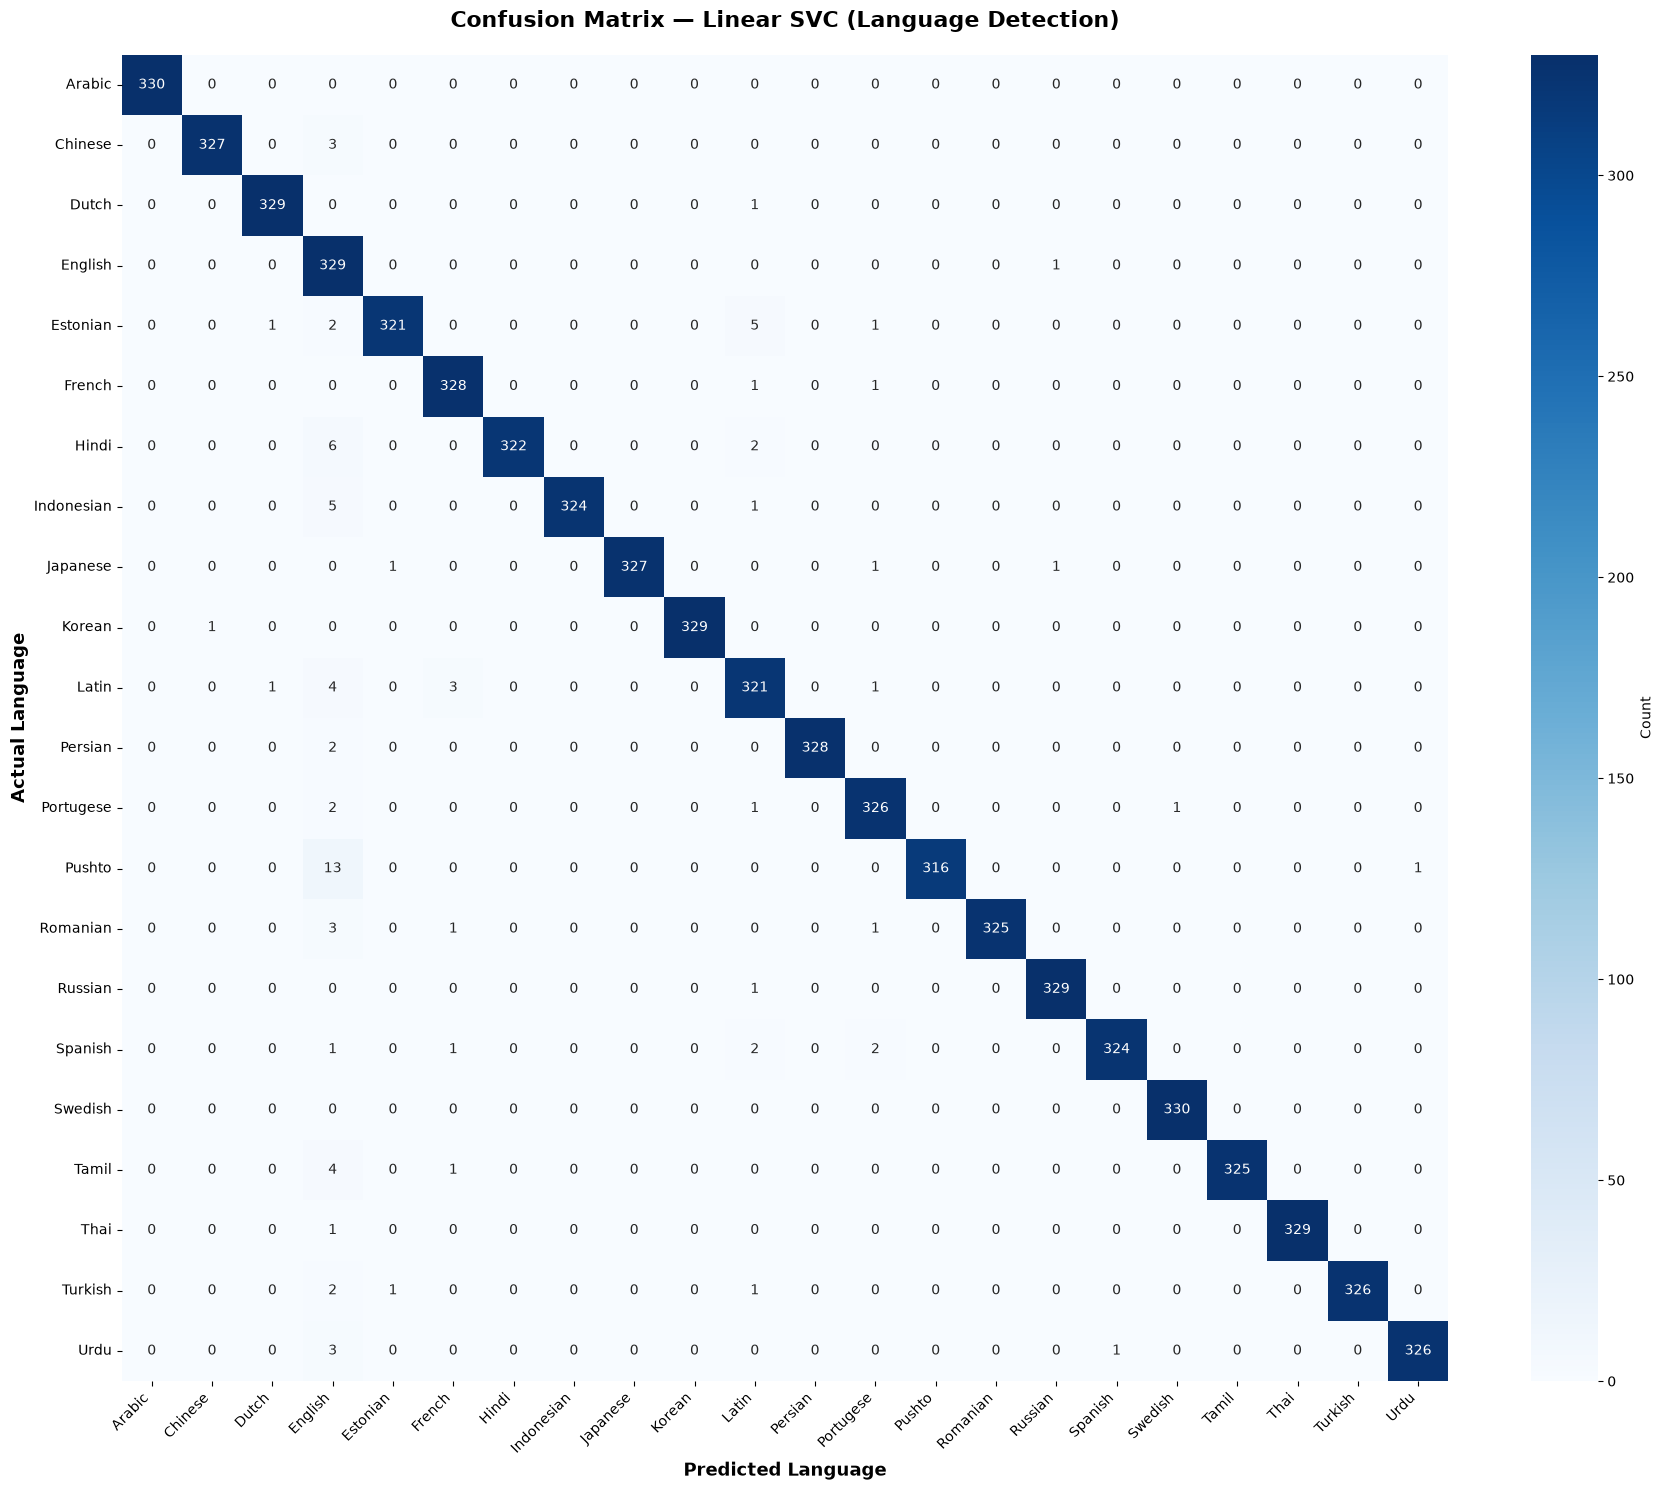

In [52]:


# Confusion matrix
cm = confusion_matrix(y_test, svc_pred)

# Class names — y_test se nikal lein (df ki zaroorat nahi)
class_names = sorted(y_test.unique())


# Heatmap
plt.figure(figsize=(18, 15))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={'label': 'Count'}
)

plt.title('Confusion Matrix — Linear SVC (Language Detection)',
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Predicted Language', fontsize=13, fontweight='bold')
plt.ylabel('Actual Language', fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()